In [2]:
# Import required libraries for data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset into a pandas DataFrame
df = pd.read_csv('amazon_sales_dataset.csv')

# Display the first 5 rows of the dataset
display(df.head())

# Print general information about the dataset structure
print(df.info())

,order_id,order_date,product_id,product_category,price,discount_percent,quantity_sold,customer_region,payment_method,rating,review_count,discounted_price,total_revenue
0,1,2022-04-13,2637,Books,128.75,10,4,North America,UPI,3.5,443,115.88,463.52
1,2,2023-03-12,2300,Fashion,302.60,20,5,Asia,Credit Card,3.7,475,242.08,1210.40
2,3,2022-09-28,3670,Sports,495.80,20,2,Europe,UPI,4.4,183,396.64,793.28
3,4,2022-04-17,2522,Books,371.95,15,4,Middle East,UPI,5.0,212,316.16,1264.64
4,5,2022-03-13,1717,Beauty,201.68,0,4,Middle East,UPI,4.6,308,201.68,806.72


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          50000 non-null  int64  
 1   order_date        50000 non-null  object 
 2   product_id        50000 non-null  int64  
 3   product_category  50000 non-null  object 
 4   price             50000 non-null  float64
 5   discount_percent  50000 non-null  int64  
 6   quantity_sold     50000 non-null  int64  
 7   customer_region   50000 non-null  object 
 8   payment_method    50000 non-null  object 
 9   rating            50000 non-null  float64
 10  review_count      50000 non-null  int64  
 11  discounted_price  50000 non-null  float64
 12  total_revenue     50000 non-null  float64
dtypes: float64(4), int64(5), object(4)
memory usage: 5.0+ MB
None


In [3]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print("--- Missing Values ---")
print(missing_values)

# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

# Check data types of all columns
print("\n--- Data Types ---")
print(df.dtypes)

--- Missing Values ---
order_id            0
order_date          0
product_id          0
product_category    0
price               0
discount_percent    0
quantity_sold       0
customer_region     0
payment_method      0
rating              0
review_count        0
discounted_price    0
total_revenue       0
dtype: int64

Number of duplicate rows: 0

--- Data Types ---
order_id              int64
order_date           object
product_id            int64
product_category     object
price               float64
discount_percent      int64
quantity_sold         int64
customer_region      object
payment_method       object
rating              float64
review_count          int64
discounted_price    float64
total_revenue       float64
dtype: object


In [4]:
# 1. Drop unnecessary ID/date columns that don't help prediction
# (We keep order_id, product_id out of features, and order_date can be dropped or ignored for simplicity)
df_model = df.drop(columns=['order_id', 'order_date', 'product_id'])

# 2. Perform One-Hot Encoding on categorical columns
df_encoded = pd.get_dummies(df_model, columns=['product_category', 'customer_region', 'payment_method'], drop_first=True)

# 3. Separate Features (X) and Target (y)
# Target (y) = total_revenue
# Features (X) = everything else
X = df_encoded.drop(columns=['total_revenue'])
y = df_encoded['total_revenue']

# Display feature shape and first few rows of X
print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")
display(X.head(2))

Features shape (X): (50000, 18)
Target shape (y): (50000,)


,price,discount_percent,quantity_sold,rating,review_count,discounted_price,product_category_Books,product_category_Electronics,product_category_Fashion,product_category_Home & Kitchen,product_category_Sports,customer_region_Europe,customer_region_Middle East,customer_region_North America,payment_method_Credit Card,payment_method_Debit Card,payment_method_UPI,payment_method_Wallet
0,128.75,10,4,3.5,443,115.88,True,False,False,False,False,False,False,True,False,False,True,False
1,302.60,20,5,3.7,475,242.08,False,False,True,False,False,False,False,False,True,False,False,False


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# 1. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shapes of our splits
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

# 2. Initialize the Random Forest Regressor model
model = RandomForestRegressor(n_estimators=100, random_state=42)
print("\nRandom Forest Regressor model initialized successfully!")

X_train shape: (40000, 18)
X_test shape: (10000, 18)
y_train shape: (40000,)
y_test shape: (10000,)

Random Forest Regressor model initialized successfully!


Training the Random Forest model...

--- Model Evaluation Results ---
R-squared (R2) Score: 1.0000
Root Mean Squared Error (RMSE): 0.1997


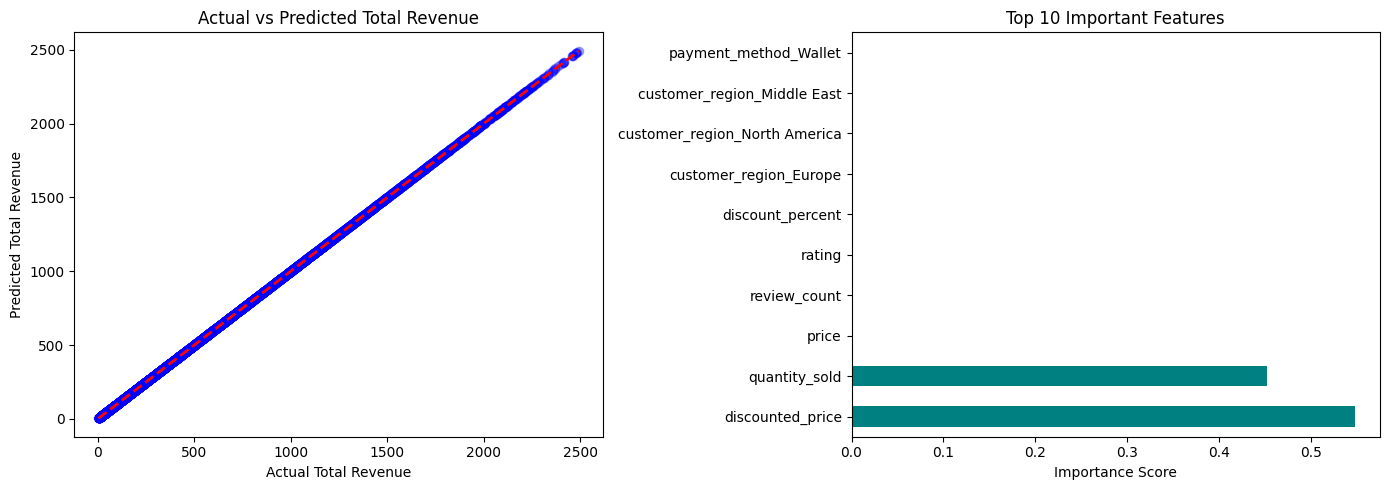

In [8]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Train (fit) the model
print("Training the Random Forest model...")
model.fit(X_train, y_train)

# 2. Make predictions on the test set
y_pred = model.predict(X_test)

# 3. Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
# Calculate RMSE by taking the square root of MSE (fully compatible with all sklearn versions)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\n--- Model Evaluation Results ---")
print(f"R-squared (R2) Score: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# 4. Generate Visualizations
plt.figure(figsize=(14, 5))

# Plot 1: Actual vs Predicted Revenue
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Total Revenue')
plt.ylabel('Predicted Total Revenue')
plt.title('Actual vs Predicted Total Revenue')

# Plot 2: Feature Importance
plt.subplot(1, 2, 2)
feature_importances = pd.Series(model.feature_importances_, index=X.columns)
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.xlabel('Importance Score')
plt.title('Top 10 Important Features')

plt.tight_layout()
plt.show()

In [9]:
import gradio as gr

# Define a prediction function for Gradio
def predict_revenue(price, discount_percent, quantity_sold, rating, review_count, discounted_price, product_category, customer_region, payment_method):
    # Create a DataFrame with a single row matching our model input structure
    input_data = pd.DataFrame(0, index=[0], columns=X.columns)

    # Fill in numerical features
    input_data['price'] = price
    input_data['discount_percent'] = discount_percent
    input_data['quantity_sold'] = quantity_sold
    input_data['rating'] = rating
    input_data['review_count'] = review_count
    input_data['discounted_price'] = discounted_price

    # Fill in categorical features via one-hot encoding columns if they exist
    cat_cols = {
        'product_category': product_category,
        'customer_region': customer_region,
        'payment_method': payment_method
    }

    for col, val in cat_cols.items():
        col_name = f"{col}_{val}"
        if col_name in input_data.columns:
            input_data[col_name] = 1

    # Predict revenue using our trained model
    predicted_rev = model.predict(input_data)[0]
    return f"${predicted_rev:,.2f}"

# Create the Gradio Interface
demo = gr.Interface(
    fn=predict_revenue,
    inputs=[
        gr.Number(label="Price ($)", value=150.0),
        gr.Slider(0, 50, label="Discount Percent (%)", value=10),
        gr.Number(label="Quantity Sold", value=3),
        gr.Slider(1.0, 5.0, label="Rating", value=4.0),
        gr.Number(label="Review Count", value=250),
        gr.Number(label="Discounted Price ($)", value=135.0),
        gr.Dropdown(["Books", "Electronics", "Fashion", "Home & Kitchen", "Sports"], label="Product Category", value="Books"),
        gr.Dropdown(["North America", "Europe", "Asia", "Middle East"], label="Customer Region", value="North America"),
        gr.Dropdown(["UPI", "Credit Card", "Debit Card", "Wallet"], label="Payment Method", value="UPI")
    ],
    outputs=gr.Textbox(label="Predicted Total Revenue"),
    title="Amazon Sales Total Revenue Predictor",
    description="Enter sales and product details to predict the total revenue using our trained Random Forest model."
)

# Launch the app directly in Colab
demo.launch(inline=True, share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e5541dfa27d8817597.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
